<a href="https://colab.research.google.com/github/pratyay2409/NLP/blob/Assignment/NLP_Activity_4_Problem_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Problem 2:

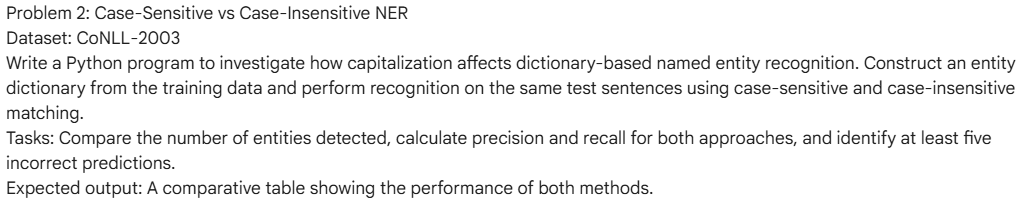

In [1]:
!pip install -q datasets

from collections import defaultdict
from datasets import load_dataset, utils

utils.logging.disable_progress_bar()

In [3]:
# Sets up BIO tag-to-entity mappings for CoNLL-2003, and loads the training data along with the test split (first 200 sentences for evaluation).
TAG_MAP = {
    1: ("B", "PER"), 2: ("I", "PER"),
    3: ("B", "ORG"), 4: ("I", "ORG"),
    5: ("B", "LOC"), 6: ("I", "LOC")
}
TARGET_TYPES = {"PER", "LOC", "ORG"}

print("Loading CoNLL-2003 dataset...")
dataset = load_dataset("BramVanroy/conll2003")
train_data = dataset["train"]
test_data = dataset["test"].select(range(200))

print(f"Loaded {len(train_data)} training samples and {len(test_data)} test sentences.")

Loading CoNLL-2003 dataset...
Loaded 14041 training samples and 200 test sentences.


In [4]:
# Helper function that reads token sequences and BIO tags to extract full entity spans as tuples: (start_index, end_index, entity_text, entity_type).

def extract_gold_entities(tokens, ner_tags):
    entities = []
    current_tokens = []
    current_type = None
    start_idx = 0

    for idx, (token, tag_id) in enumerate(zip(tokens, ner_tags)):
        prefix, ent_type = TAG_MAP.get(tag_id, ("O", None))

        if prefix == "B":
            if current_type and current_type in TARGET_TYPES:
                entities.append((start_idx, idx, " ".join(current_tokens), current_type))
            current_tokens = [token]
            current_type = ent_type
            start_idx = idx
        elif prefix == "I" and current_type == ent_type:
            current_tokens.append(token)
        else:
            if current_type and current_type in TARGET_TYPES:
                entities.append((start_idx, idx, " ".join(current_tokens), current_type))
            current_tokens = []
            current_type = None

    if current_type and current_type in TARGET_TYPES:
        entities.append((start_idx, len(tokens), " ".join(current_tokens), current_type))

    return entities

In [5]:
# Builds two separate dictionary mappings from training data:
# 1. Case-sensitive dictionary (preserves exact capitalization).
# 2. Case-insensitive dictionary (lowercased phrases).
# Resolves cross-type conflicts via frequency voting and calculates maximum phrase lengths.

case_sensitive_counts = defaultdict(lambda: defaultdict(int))
case_insensitive_counts = defaultdict(lambda: defaultdict(int))

for sample in train_data:
    entities = extract_gold_entities(sample["tokens"], sample["ner_tags"])
    for _, _, text, ent_type in entities:
        # Case-sensitive token tuple
        tokens_cs = tuple(text.split())
        case_sensitive_counts[tokens_cs][ent_type] += 1

        # Case-insensitive token tuple (lowercased)
        tokens_ci = tuple(text.lower().split())
        case_insensitive_counts[tokens_ci][ent_type] += 1

dict_cs = {t: set() for t in TARGET_TYPES}
for token_tuple, counts in case_sensitive_counts.items():
    best_type = max(counts, key=counts.get)
    dict_cs[best_type].add(token_tuple)

dict_ci = {t: set() for t in TARGET_TYPES}
for token_tuple, counts in case_insensitive_counts.items():
    best_type = max(counts, key=counts.get)
    dict_ci[best_type].add(token_tuple)

max_len_cs = max((len(t) for d in dict_cs.values() for t in d), default=1)
max_len_ci = max((len(t) for d in dict_ci.values() for t in d), default=1)

print("=== Dictionary Statistics ===")
print(f"Case-Sensitive unique entries:   {sum(len(d) for d in dict_cs.values())}")
print(f"Case-Insensitive unique entries: {sum(len(d) for d in dict_ci.values())}")

=== Dictionary Statistics ===
Case-Sensitive unique entries:   7223
Case-Insensitive unique entries: 6835


In [6]:
# Implements greedy longest-phrase matching configurable for either case-sensitive or case-insensitive matching across token streams.

def longest_phrase_match(tokens, dictionaries, max_len, case_sensitive=True):
    n = len(tokens)
    matched_entities = []
    lookup_tokens = tokens if case_sensitive else [t.lower() for t in tokens]
    i = 0

    while i < n:
        matched = False
        for length in range(min(max_len, n - i), 0, -1):
            span_tuple = tuple(lookup_tokens[i : i + length])
            for ent_type in TARGET_TYPES:
                if span_tuple in dictionaries[ent_type]:
                    orig_text = " ".join(tokens[i : i + length])
                    matched_entities.append((i, i + length, orig_text, ent_type))
                    i += length
                    matched = True
                    break
            if matched:
                break
        if not matched:
            i += 1

    return matched_entities

# Run matching under both settings on the test split
gold_all = []
pred_cs_all = []
pred_ci_all = []

for sample in test_data:
    gold = extract_gold_entities(sample["tokens"], sample["ner_tags"])
    pred_cs = longest_phrase_match(sample["tokens"], dict_cs, max_len_cs, case_sensitive=True)
    pred_ci = longest_phrase_match(sample["tokens"], dict_ci, max_len_ci, case_sensitive=False)

    gold_all.append(gold)
    pred_cs_all.append(pred_cs)
    pred_ci_all.append(pred_ci)

print(f"Executed matching on {len(test_data)} sentences under both modes.")

Executed matching on 200 sentences under both modes.


In [7]:
# Evaluates total detected entities, true positives, false positives, false negatives, precision, recall, and F1-score for both approaches, and outputs a comparative table.

def evaluate_predictions(gold_list, pred_list):
    total_detected = sum(len(p) for p in pred_list)
    tp = fp = fn = 0

    for gold, pred in zip(gold_list, pred_list):
        gold_set = {(start, end, ent_type) for start, end, _, ent_type in gold}
        pred_set = {(start, end, ent_type) for start, end, _, ent_type in pred}

        tp += len(gold_set & pred_set)
        fp += len(pred_set - gold_set)
        fn += len(gold_set - pred_set)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    return total_detected, tp, fp, fn, precision, recall, f1

tot_cs, tp_cs, fp_cs, fn_cs, p_cs, r_cs, f1_cs = evaluate_predictions(gold_all, pred_cs_all)
tot_ci, tp_ci, fp_ci, fn_ci, p_ci, r_ci, f1_ci = evaluate_predictions(gold_all, pred_ci_all)

print("=== Comparative Performance Table ===")
row_fmt = "{:<20} | {:<16} | {:<6} | {:<6} | {:<6} | {:<11} | {:<11} | {:<11}"
header = row_fmt.format("Method", "Entities Detected", "TP", "FP", "FN", "Precision", "Recall", "F1-Score")
print(header)
print("-" * len(header))
print(row_fmt.format("Case-Sensitive", tot_cs, tp_cs, fp_cs, fn_cs, f"{p_cs:.4f}", f"{r_cs:.4f}", f"{f1_cs:.4f}"))
print(row_fmt.format("Case-Insensitive", tot_ci, tp_ci, fp_ci, fn_ci, f"{p_ci:.4f}", f"{r_ci:.4f}", f"{f1_ci:.4f}"))

=== Comparative Performance Table ===
Method               | Entities Detected | TP     | FP     | FN     | Precision   | Recall      | F1-Score   
-------------------------------------------------------------------------------------------------------------
Case-Sensitive       | 204              | 158    | 46     | 214    | 0.7745      | 0.4247      | 0.5486     
Case-Insensitive     | 321              | 163    | 158    | 209    | 0.5078      | 0.4382      | 0.4704     


In [10]:
# Scans sentences to extract at least five distinct incorrect predictions (False Positives or type mismatches) caused by case-insensitivity, showing sentence context and the root cause.

incorrect_examples = []

for idx, (sample, gold, pred_ci) in enumerate(zip(test_data, gold_all, pred_ci_all)):
    gold_dict = {(start, end): (text, ent_type) for start, end, text, ent_type in gold}
    pred_set = {(start, end, text, ent_type) for start, end, text, ent_type in pred_ci}

    for start, end, text, ent_type in pred_set:
        # Check if the prediction is not an exact match in the gold standard
        if (start, end) not in gold_dict or gold_dict[(start, end)][1] != ent_type:
            gold_label = gold_dict.get((start, end), ("None", "O"))[1]
            sentence_str = " ".join(sample["tokens"])
            incorrect_examples.append({
                "sentence": sentence_str,
                "phrase": text,
                "predicted_type": ent_type,
                "gold_type": gold_label
            })
            if len(incorrect_examples) >= 5:
                break
    if len(incorrect_examples) >= 5:
        break

print("=== The Incorrect Predictions (Case-Insensitive Errors) ===\n")
for i, err in enumerate(incorrect_examples, 1):
    print(f"Error {i}:")
    print(f"  Phrase:          '{err['phrase']}'")
    print(f"  Predicted Type:  {err['predicted_type']}")
    print(f"  Actual Gold Tag: {err['gold_type']}")
    print(f"  Sentence:        \"{err['sentence']}\"\n")

=== The Incorrect Predictions (Case-Insensitive Errors) ===

Error 1:
  Phrase:          'CHINA'
  Predicted Type:  LOC
  Actual Gold Tag: PER
  Sentence:        "SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT ."

Error 2:
  Phrase:          'the'
  Predicted Type:  LOC
  Actual Gold Tag: O
  Sentence:        "Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday ."

Error 3:
  Phrase:          'defence'
  Predicted Type:  ORG
  Actual Gold Tag: O
  Sentence:        "Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday ."

Error 4:
  Phrase:          'the'
  Predicted Type:  LOC
  Actual Gold Tag: O
  Sentence:        "But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcomers Uzbekistan ."

Error 5:
  Phrase:          'the'
  Predicted Type:  LOC
  Actual Gold Tag: O
  Sente